# Cognitive Load Baseline

Dummy and XGBoost with participant-level evaluation. Start with smoke mode; use full mode for the baseline report.

### Mount Google Drive

In [10]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Setup

Copy `shared` and `requirements.txt` into the project's `models` folder before running. If installation requires a runtime restart, restart and run the notebook from the beginning.

In [11]:
from pathlib import Path
import subprocess
import sys

ROOT = Path('/content/drive/MyDrive/Penelitian-Adaptive-IDE')
MODELS_DIR = ROOT / 'models'
requirements = MODELS_DIR / 'requirements.txt'
if not requirements.is_file():
    raise FileNotFoundError(f'Missing requirements: {requirements}')
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(requirements)])

0

### Configuration

In [12]:
import json
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(MODELS_DIR))
from shared.baseline import RunConfig, describe_data, load_dataset, make_folds, run_experiment

DATASET_PATH = ROOT / 'Dataset' / 'good_acceptable.csv'
OUTPUT_ROOT = MODELS_DIR / 'outputs' / 'exp01'
MODE = 'full'
SEED = 42
RESUME_DIR = None  # Set to the complete run directory path to resume.

config = RunConfig(DATASET_PATH, OUTPUT_ROOT, mode=MODE, seed=SEED)

### Dataset

In [13]:
data = load_dataset(DATASET_PATH)
dataset_summary = describe_data(data)
print(f"Windows: {dataset_summary['rows']}; participants: {dataset_summary['participants']}")
display(data['difficulty_level'].value_counts().rename('windows').to_frame())
display(pd.crosstab(data['participant_id'], data['difficulty_level']))
display(pd.Series(dataset_summary['missing_features'], name='missing').to_frame())

Windows: 2294; participants: 13


,windows
difficulty_level,
hard,1077
medium,968
easy,249


difficulty_level,easy,hard,medium
participant_id,,,
Andrean,25,136,86
Andreas,10,65,55
Athaya,16,91,59
Fabian,45,117,81
Rafi,28,143,101
Savitri,7,110,78
Shakilla,0,0,88
Tio,14,104,75
faqih,29,116,81


,missing
rmssd_ms,0
sdnn_ms,0
rmssd_baseline_ratio,193
blink_count,0
blink_rate_per_minute,0
ear_left_mean,0
ear_left_std,0
ear_right_mean,0
ear_right_std,0
iris_size_estimate_mean,0


### Evaluation Folds

All recordings from the held-out participant remain outside training. Inner folds are recorded for later experiments; this baseline does not tune parameters.

In [14]:
folds = make_folds(data)
fold_table = pd.DataFrame([
    {'fold': f['fold_id'], 'test_participant': f['participant_id'],
     'train_windows': len(f['train_ids']), 'test_windows': len(f['test_ids']),
     'inner_folds': len(f['inner'])}
    for f in folds
])
display(fold_table)
print('Smoke: first outer fold, 10 trees. Full: all outer folds, 300 trees.')

,fold,test_participant,train_windows,test_windows,inner_folds
0,fold_00,Andrean,2047,247,3
1,fold_01,Andreas,2164,130,3
2,fold_02,Athaya,2128,166,3
3,fold_03,Fabian,2051,243,3
4,fold_04,Rafi,2022,272,3
5,fold_05,Savitri,2099,195,3
6,fold_06,Shakilla,2206,88,3
7,fold_07,Tio,2101,193,3
8,fold_08,faqih,2068,226,3
9,fold_09,ikhsan,2082,212,3


Smoke: first outer fold, 10 trees. Full: all outer folds, 300 trees.


### Training

The run directory is printed before training. Keep this path to resume an interrupted run. A resume requires the same data, mode, seed, code, and dependency versions. Do not run two writers against the same run directory.

In [15]:
run_dir = run_experiment(config, resume_dir=RESUME_DIR)
print(run_dir)

Run directory: /content/drive/.shortcut-targets-by-id/1UUN1XmTGZ26yyLZDlQJn_pKn7-zFwLGg/Penelitian-Adaptive-IDE/models/outputs/exp01/20261114T054940956475Z_full_d2dbf4b4
fold_00 / Andrean / dummy: training
fold_00 / Andrean / xgboost: training
fold_01 / Andreas / dummy: training
fold_01 / Andreas / xgboost: training
fold_02 / Athaya / dummy: training
fold_02 / Athaya / xgboost: training
fold_03 / Fabian / dummy: training
fold_03 / Fabian / xgboost: training
fold_04 / Rafi / dummy: training
fold_04 / Rafi / xgboost: training
fold_05 / Savitri / dummy: training
fold_05 / Savitri / xgboost: training
fold_06 / Shakilla / dummy: training
fold_06 / Shakilla / xgboost: training
fold_07 / Tio / dummy: training
fold_07 / Tio / xgboost: training
fold_08 / faqih / dummy: training
fold_08 / faqih / xgboost: training
fold_09 / ikhsan / dummy: training
fold_09 / ikhsan / xgboost: training
fold_10 / kaka / dummy: training
fold_10 / kaka / xgboost: training
fold_11 / raina / dummy: training
fold_11 / 

### Evaluation

Smoke results are technical checks, not the full research evaluation. Macro-F1 in the pooled metrics uses all three labels. Participant metrics also report macro-F1 over classes present in that participant's test data. Blank class metrics mean that the test data has no examples of that class.

In [16]:
summary = json.loads((run_dir / 'summary.json').read_text(encoding='utf-8'))
print(summary)
if summary['status'] != 'complete':
    raise RuntimeError('The run is incomplete; do not use its aggregate report.')
if summary['mode'] == 'smoke':
    print('Smoke test only. Run MODE = "full" for the baseline evaluation.')

display(pd.read_csv(run_dir / 'metrics.csv'))
class_metrics = pd.read_csv(run_dir / 'class_metrics.csv')
display(class_metrics[class_metrics['scope'] == 'pooled'])
display(pd.read_csv(run_dir / 'participant_metrics.csv'))
display(pd.read_csv(run_dir / 'participant_summary.csv', header=[0, 1], index_col=0))

{'completed_at': '2026-11-14T05:50:07.700040+00:00', 'completed_units': 26, 'evaluated_folds': 13, 'mode': 'full', 'prediction_rows': 4588, 'scheduled_folds': 13, 'status': 'complete', 'total_folds': 13}


,model,accuracy,balanced_accuracy,macro_f1,macro_f1_present_classes,windows
0,dummy,0.469486,0.333333,0.212993,0.212993,2294
1,xgboost,0.357018,0.277400,0.278570,0.278570,2294


,model,scope,participant_id,label,support,precision,recall,f1
0,dummy,pooled,NaN,Low,249,0.000000,0.000000,0.000000
1,dummy,pooled,NaN,Medium,968,0.000000,0.000000,0.000000
2,dummy,pooled,NaN,High,1077,0.469486,1.000000,0.638980
42,xgboost,pooled,NaN,Low,249,0.034965,0.040161,0.037383
43,xgboost,pooled,NaN,Medium,968,0.391391,0.403926,0.397560
44,xgboost,pooled,NaN,High,1077,0.414272,0.388115,0.400767


,model,participant_id,accuracy,balanced_accuracy,macro_f1_present_classes,windows
0,dummy,Andrean,0.550607,0.333333,0.236728,247
1,dummy,Andreas,0.500000,0.333333,0.222222,130
2,dummy,Athaya,0.548193,0.333333,0.236057,166
3,dummy,Fabian,0.481481,0.333333,0.216667,243
4,dummy,Rafi,0.525735,0.333333,0.229719,272
5,dummy,Savitri,0.564103,0.333333,0.240437,195
6,dummy,Shakilla,0.000000,0.000000,0.000000,88
7,dummy,Tio,0.538860,0.333333,0.233446,193
8,dummy,faqih,0.513274,0.333333,0.226121,226
9,dummy,ikhsan,0.556604,0.500000,0.357576,212


accuracy           balanced_accuracy            \
             mean       std              mean       std   
model                                                     
dummy    0.437076  0.200437          0.294872  0.138675   
xgboost  0.335415  0.170186          0.269442  0.131663   

        macro_f1_present_classes            
                            mean       std  
model                                       
dummy                   0.200823  0.097485  
xgboost                 0.239349  0.114721

### Confusion Matrices

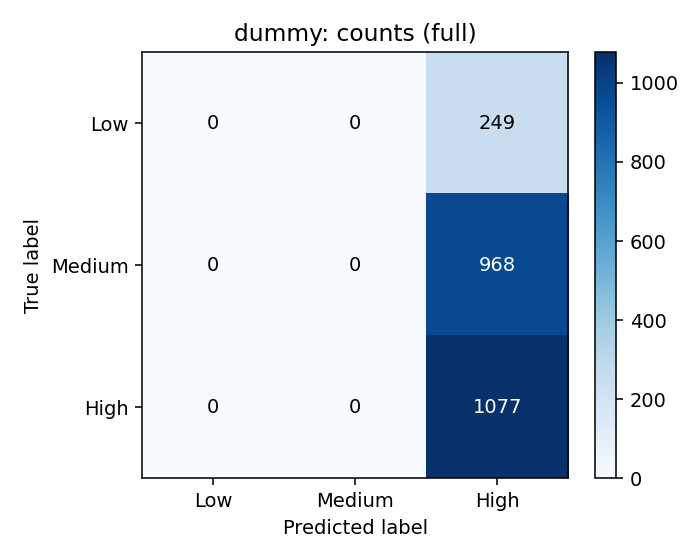

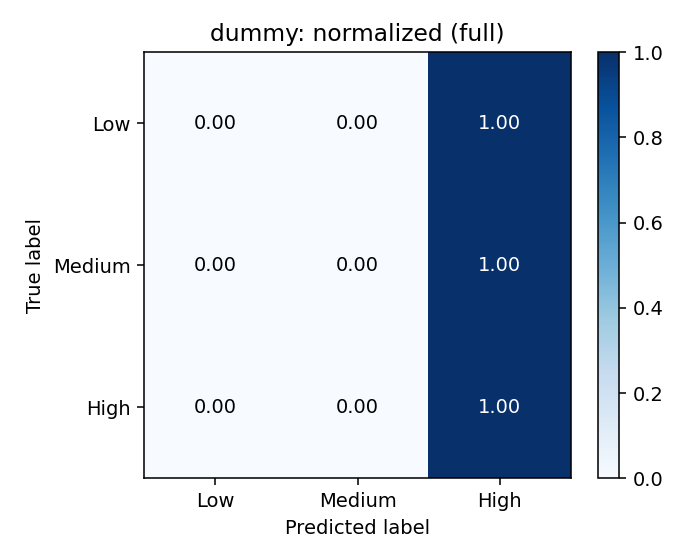

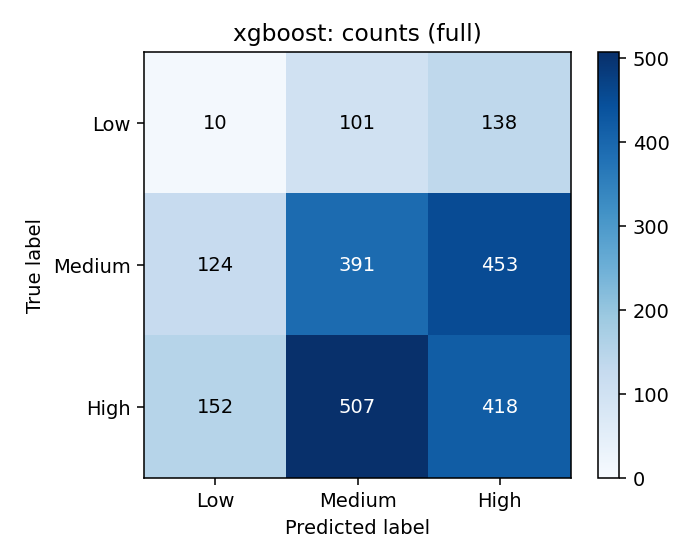

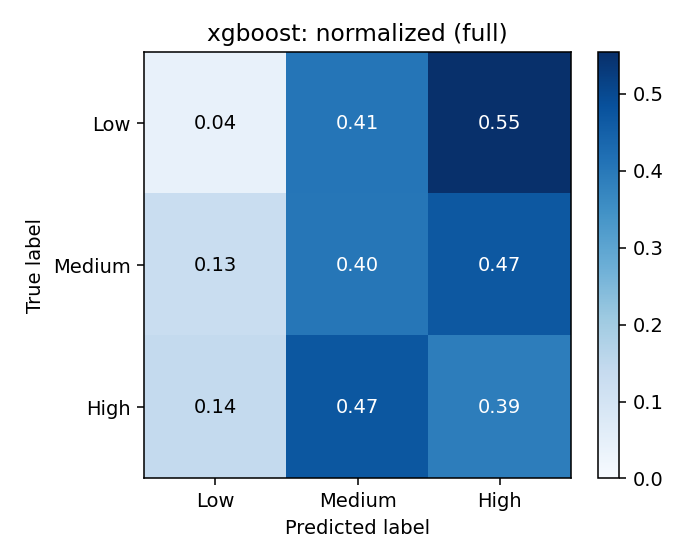

In [17]:
for model_name in ['dummy', 'xgboost']:
    for matrix_type in ['counts', 'normalized']:
        display(Image(filename=str(run_dir / 'figures' / f'{model_name}_{matrix_type}.png')))

### Saved Results

`predictions.csv` contains held-out predictions. `fold_manifest.json` records the split. Each `folds/<fold>/<model>` directory contains preprocessing, a fitted pipeline, timing, and a completion checksum. Only load `.joblib` files from trusted sources.

In [18]:
predictions = pd.read_csv(run_dir / 'predictions.csv')
display(predictions.head())
print('Output directory:', run_dir)
print('Prediction rows:', len(predictions))
print('Environment:', run_dir / 'environment.json')
print('Dependency versions:', run_dir / 'environment-lock.txt')

,window_id,participant_id,session_id,model,fold_id,y_true,y_pred,true_label,predicted_label,prob_Low,prob_Medium,prob_High
0,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,dummy,fold_00,0,2,Low,High,0.0,0.0,1.0
1,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,dummy,fold_00,0,2,Low,High,0.0,0.0,1.0
2,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,dummy,fold_00,0,2,Low,High,0.0,0.0,1.0
3,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,dummy,fold_00,0,2,Low,High,0.0,0.0,1.0
4,20261030_101138_P01_coding_task|2026-10-30T10:...,Andrean,20261030_101138_P01_coding_task,dummy,fold_00,0,2,Low,High,0.0,0.0,1.0


Output directory: /content/drive/.shortcut-targets-by-id/1UUN1XmTGZ26yyLZDlQJn_pKn7-zFwLGg/Penelitian-Adaptive-IDE/models/outputs/exp01/20261114T054940956475Z_full_d2dbf4b4
Prediction rows: 4588
Environment: /content/drive/.shortcut-targets-by-id/1UUN1XmTGZ26yyLZDlQJn_pKn7-zFwLGg/Penelitian-Adaptive-IDE/models/outputs/exp01/20261114T054940956475Z_full_d2dbf4b4/environment.json
Dependency versions: /content/drive/.shortcut-targets-by-id/1UUN1XmTGZ26yyLZDlQJn_pKn7-zFwLGg/Penelitian-Adaptive-IDE/models/outputs/exp01/20261114T054940956475Z_full_d2dbf4b4/environment-lock.txt
